# Existe relação entre o tipo de manifestação clínica inicial e o tempo até o diagnóstico?

In [2]:
# IMPORTA BIBLIOTECAS

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import re
from datetime import datetime
from datetime import date
from scipy.stats import chi2_contingency
import numpy as np
from dateutil.relativedelta import relativedelta
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats import chi2
from scipy.stats import chi2_contingency, fisher_exact
from matplotlib.ticker import PercentFormatter # Importando o formatador de porcentagem



# Importa os dados

In [5]:
df = pd.read_excel(
    "dados_atualizado.xlsx",
    sheet_name=0,
    header=1,          # usa a 2ª linha como cabeçalho real
    dtype={"Class. Por idade": str},  # evita converter "1" em número se quiser
)


## Criando Pipeline de Limpeza dos Dados ### Ajustar muita coisa aqui pode ser otimizada

In [7]:
def limpa_dados(df):
    
    colunas_data = ["data_nascimento","data_primeira_consulta","data_primeira_colonoscopia"]

    def padroniza_colunas(df):
        df.columns = (df.columns.astype(str).str.replace("\n", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip())
        return df

    def renomeia_colunas(df):
        df = df.rename(columns={
            "Nome": "nome",
            "Class. Por idade": "classificacao_idade",
            "Data nascimento": "data_nascimento",
            "Data 1ª consulta": "data_primeira_consulta",
            "Tempo entre início dos sintomas e primeira consulta": "intervalo_sintomas_primeira_consulta",
            "Sexo": "sexo",
            "Tipo": "tipo",
            "Perda de peso": "perda_peso",
            "Idade (meses) início dos sintomas": "idade_inicio_sintomas",
            "Data 1ª colono": "data_primeira_colonoscopia",
            "Unnamed: 10": "intervalo_sintomas_primeira_colonoscopia",
            "Classificação": "diagnostico",
        })
        return df

    def formata_colunas_data(df):
        for coluna in colunas_data:
            df[coluna] = (pd.to_datetime(df[coluna], errors="coerce").dt.strftime("%d/%m/%Y"))
        return df

    def deixar_coluna_inteira(df, coluna):
        for index, tempo in enumerate(df[coluna].tolist()):
            if tempo != '?':
                numero = int(re.sub(r"\D", "", tempo))
                df.loc[index, coluna] = numero
            elif tempo == "?":
                df.loc[index, coluna] = -1
            df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
            df[coluna] = df[coluna].astype("Int64")
        return df

        
    def criar_coluna(df, coluna):
        datas = pd.to_datetime(df['data_nascimento'],format="%d/%m/%Y",errors="coerce")
        meses = df["idade_inicio_sintomas"]
        df[coluna] = [d + pd.DateOffset(months=int(m)) if pd.notna(d) and pd.notna(m) else pd.NaT for d, m in zip(datas, meses)  ]
        df[coluna] = (pd.to_datetime(df[coluna],errors="coerce" ).dt.strftime("%d/%m/%Y") )
        return df

    

    def ajustar_coluna_tipo(df):
        for index, tipo in enumerate(df['tipo'].tolist()):
            if tipo== 'Diarreia ':
                  df.loc[index, "tipo"] = 'Diarreia'
            
        return df
        
    def ajustar_coluna_classificacao_idade(df):
        for index, classificacao in enumerate(df['classificacao_idade'].tolist()):
            if classificacao== 'VEOIBD ':
                  df.loc[index, "classificacao_idade"] = 'VEOIBD'
            
        return df    
        
    def padronizar_sim_nao(df):
        for index, resposta in enumerate(df['perda_peso'].tolist()):
            if resposta == "não" or resposta == 'Não':
                  df.loc[index, "perda_peso"] = 'N'
            else:
                df.loc[index, "perda_peso"] = 'S'
        return df   


    def calcula_intervalo_colonoscopia(df):
        resultados = []
        for index in range(len(df)):
            d1_str = df.loc[index, "data_inicio_sintomas"]
            d2_str = df.loc[index, "data_primeira_colonoscopia"]
            # 1) converte para datetime
            try:
                d1 = datetime.strptime(d1_str, "%d/%m/%Y")
                d2 = datetime.strptime(d2_str, "%d/%m/%Y")
            except (ValueError, TypeError):
                resultados.append(None)
                continue
            # 2) valida ordem
            if d2 <= d1:
                resultados.append(None)
                continue
            # 3) calcula meses completos
            meses = ((d2.year - d1.year) * 12 + (d2.month - d1.month) - (d2.day < d1.day))

            resultados.append(meses)

        df["intervalo_sintomas_primeira_colonoscopia_recalculado"] = resultados
        df["intervalo_sintomas_primeira_colonoscopia_recalculado"] = pd.to_numeric(df["intervalo_sintomas_primeira_colonoscopia_recalculado"],errors="coerce")
        df["intervalo_sintomas_primeira_colonoscopia_recalculado"] = df["intervalo_sintomas_primeira_colonoscopia_recalculado"].astype("Int64")

        return df


    df = df.drop(index=0).reset_index(drop=True)
    df = padroniza_colunas(df)
    df = renomeia_colunas(df)
    df = formata_colunas_data(df)
    df = df.drop(columns=["nome"])
    df = deixar_coluna_inteira(df,"intervalo_sintomas_primeira_consulta")
    df = deixar_coluna_inteira(df,"intervalo_sintomas_primeira_colonoscopia")
    df = criar_coluna(df,"data_inicio_sintomas")  
    df = calcula_intervalo_colonoscopia(df)
    df = padronizar_sim_nao(df)
    df = ajustar_coluna_tipo(df)
    df = ajustar_coluna_classificacao_idade(df)

    return df

In [8]:
# Tipo =  Sintomas iniciais
dados_df = limpa_dados(df)
dados_df = dados_df[dados_df["intervalo_sintomas_primeira_consulta"]!=-1]
dados_df = dados_df.drop(columns=['intervalo_sintomas_primeira_colonoscopia_recalculado'])


# Funcao que calcula intervalo em meses entre duas datas 

In [10]:
# Essa funcao vai generalizar e vai sempre me devolver o valor em meses entre duas datas ....
def calcular_intervalo_datas(data_maior,data_menor,nome_coluna):
    dados_df[data_maior] = pd.to_datetime(dados_df[data_maior], format='%d/%m/%Y', errors='coerce')
    dados_df[data_menor] = pd.to_datetime(dados_df[data_menor], format='%d/%m/%Y', errors='coerce')

    dados_df[nome_coluna] = (
        (dados_df[data_maior] - dados_df[data_menor]).dt.days / 30.44
    ).round(1)

## Criando coluna idade_primeira_consulta

In [12]:
# Idade Primeira Consulta = Data Primeira Consulta  -  Data Nascimento 
calcular_intervalo_datas('data_primeira_consulta','data_nascimento','idade_primeira_consulta')

## Criando coluna tempo_diagnostico



In [14]:
# Tempo Diagnostico = Data Primeira Colonoscopia - Data Inicio Sintomas
calcular_intervalo_datas('data_primeira_colonoscopia','data_inicio_sintomas','tempo_diagnostico')

## Criando coluna tempo_consulta

In [16]:
# Tempo Consulta = Data Primeira Consulta - Data Inicio Sintomas
calcular_intervalo_datas('data_primeira_consulta','data_inicio_sintomas','tempo_consulta')

In [17]:
# dados_df[dados_df['tempo_diagnostico'] < 0]

In [18]:
Ate aqui o codigo nao quebra 

SyntaxError: invalid syntax (3671462128.py, line 1)

In [49]:
# idade_inicio_sintomas
# idade_primeira_consulta
# tempo_diagnostico
# tempo_consulta

# coluna = 'tempo_consulta'

# print(f' Média : ',dados_df[coluna].mean()) 
# print(f' Desvio-Padrão : ',dados_df[coluna].std()) 
# print(f' Mediana : ',dados_df[coluna].median()) 
# print(f' Q1 : ',dados_df[coluna].quantile(0.25)) # Primeiro quartil
# print(f' Q3 : ',dados_df[coluna].quantile(0.75)) # Terceiro quartil
# print(f' Minimo : ',dados_df[coluna].min())
# print(f' Maximo : ',dados_df[coluna].max())

In [51]:
## Quebra o dataset
mulheres_df = dados_df[dados_df['sexo'] == 'F']
homens_df = dados_df[dados_df['sexo'] == 'M']

# Corrigindo graficos relatorio INICIO

# Definindo cores padrão

In [ ]:
 
HOMENS   = "#00539C"
MULHERES = "#C06C84"


CU = "#E07B39"
DC = "#00539C"
CNC = "#9DB9D3"


# Figura 1: Distribuição dos pacientes segundo o sexo

In [ ]:


# 1. Definindo os dados
categorias = ['Feminino', 'Masculino']
valores = [len(mulheres_df), len(homens_df)]
cores = [MULHERES, HOMENS] 

# 2. Configurando a figura
fig, ax = plt.subplots(figsize=(8, 6))

# 3. Criando as barras
barras = ax.bar(categorias, valores, color=cores, edgecolor='black', width=0.5)

# 4. Adicionando os rótulos de dados (n=44 e 56)
ax.text(0, 45, 'n = 44', ha='center', va='bottom', fontsize=11, color='black')
ax.text(1, 57, 'n = 56', ha='center', va='bottom', fontsize=11, color='black')

# 5. Customizando os eixos
# ax.set_title('Distribuição dos pacientes segundo o sexo', pad=20, fontsize=12)
ax.set_xlabel("Sexo", fontsize=12, fontweight='bold')
ax.set_ylabel("Pacientes (%)", fontsize=12, fontweight='bold')

# Configurando o eixo Y
ax.set_ylim(0, 65) 
ax.set_yticks([0, 20, 40, 60])
ax.set_yticklabels(['0%', '20%', '40%', '60%'])

# 6. Grade e bordas
ax.yaxis.grid(True, linestyle='-', which='major', color='lightgrey', alpha=0.7)
ax.set_axisbelow(True) 

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('lightgrey')
ax.spines['bottom'].set_color('lightgrey')

# 7. Salvando o gráfico
# Salvando em PDF (Vetorial - Recomendado para Overleaf)
# plt.savefig('grafico_sexo.pdf', format='pdf', bbox_inches='tight')

# Salvando também em PNG (Alta resolução - Caso prefira)
plt.savefig('grafico_barras_sexo.png', format='png', dpi=300, bbox_inches='tight')

# Exibindo na tela
plt.tight_layout()
plt.show()

# Figura 2: Distribuição dos pacientes segundo a idade de início dos sintomas

In [ ]:

# idades_meses = dados_df['idade_inicio_sintomas'].dropna()
idades_meses = dados_df['idade_inicio_sintomas'].dropna()
media = idades_meses.mean()
mediana = idades_meses.median()
desvio = idades_meses.std()
n_pacientes = len(idades_meses)

# --- 2. CONFIGURAÇÃO VISUAL ---
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))

# --- 3. CRIANDO OS BINS EXATOS (0-10, 10-20, etc) ---
bins_exatos = np.arange(0, 215, 10)

# --- 4. PLOTAGEM DO HISTOGRAMA ---
sns.histplot(
    idades_meses, 
    bins=bins_exatos, 
    stat='percent', 
    color='#4C72B0', 
    edgecolor='white', 
    linewidth=1.2,
    alpha=0.85,
    ax=ax
)

# --- 5. ADICIONANDO O PERCENTUAL EM CIMA DE CADA BARRA ---
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        x_pos = p.get_x() + p.get_width() / 2
        ax.text(
            x_pos, 
            altura + 0.15, 
            f"{altura:.1f}%", 
            ha='center', 
            va='bottom', 
            fontsize=8.5, 
            color='#333333',
            fontweight='bold'
        )

# --- 6. LINHAS DE MÉDIA E MEDIANA ---
ax.axvline(media, color='#C44E52', linestyle='-', linewidth=2, label=f'Média ({media:.1f} meses)')
ax.axvline(mediana, color='#8172B3', linestyle='-.', linewidth=2, label=f'Mediana ({mediana:.1f} meses)')


props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#cccccc')

ax.set_xlabel("Idade (meses)", fontsize=12, fontweight='bold')
ax.set_ylabel("Pacientes (%) ", fontsize=12, fontweight='bold')

# Eixo X: Mostrando o início de cada faixa
ax.set_xticks(np.arange(0, 211, 10))
ax.set_xlim(0, 215) # Limita o final do gráfico

y_max = ax.get_ylim()[1]
ax.set_ylim(0, y_max * 1.15) 

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legenda mais discreta
ax.legend(frameon=True, facecolor='white', framealpha=0.8, loc='upper right')

# Ajusta o layout para caber a nota de rodapé
plt.tight_layout(rect=[0, 0.03, 1, 1]) 

# --- 9. SALVANDO O GRÁFICO (OBRIGATORIAMENTE ANTES DO SHOW) ---
nome_arquivo = "idade_meses_inicio_sintomas_histograma.png" 

plt.savefig(
    nome_arquivo, 
    dpi=300,              # Alta resolução
    bbox_inches='tight',  # Remove espaços em branco
    facecolor='white'     # Fundo branco
)


plt.show()

# Criando grafico de barras CLASS ETARIA  fig 3

In [ ]:


# --- 1. PREPARAÇÃO DOS DADOS ---
dados_categoria = pd.DataFrame({
    'Classificação': ['DII Ped', 'Início precoce', 'VEOIBD'],
    'Pacientes': [39, 14, 47],
    'Porcentagem': [39.0, 14.0, 47.0]
})

# --- 2. CONFIGURAÇÃO VISUAL ---
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# --- 3. DEFININDO AS CORES DAS BARRAS ---
# Aqui você escolhe a cor de cada barra na ordem em que aparecem no eixo X
# Exemplo: Azul, Laranja e Verde. Sinta-se livre para trocar os códigos HEX.
cores_barras = [CU, DC, CNC] 

# --- 4. PLOTAGEM DAS BARRAS ---
barras = sns.barplot(
    data=dados_categoria, 
    x='Classificação', 
    y='Porcentagem', 
    palette=cores_barras, # <--- AQUI ESTÁ A MUDANÇA (usando palette em vez de color)
    edgecolor='#333333', 
    linewidth=1.2,
    width=0.6, 
    ax=ax
)

# --- 5. ADICIONANDO O TEXTO "n = XX" ACIMA DAS BARRAS ---
for i, p in enumerate(ax.patches):
    altura = p.get_height()
    n_pacientes = dados_categoria['Pacientes'].iloc[i]
    
    x_pos = p.get_x() + p.get_width() / 2
    y_pos = altura + 1.5
    
    ax.text(
        x_pos, 
        y_pos, 
        f"n = {n_pacientes}", 
        ha='center',     
        va='bottom',     
        fontsize=12,     
        color='black',   
        fontfamily='sans-serif'
    )

# --- 6. AJUSTES DE EIXOS E TÍTULOS ---
ax.set_xlabel("Classificação etária", fontsize=12, fontweight='bold')
ax.set_ylabel("Pacientes (%)", fontsize=12, fontweight='bold')

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))

ax.set_ylim(0, 55) 

ax.grid(axis='x', visible=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', color='#E0E0E0', linestyle='-', linewidth=1)

plt.tight_layout()

# --- 7. SALVANDO E EXIBINDO ---
nome_arquivo = "class_etaria_histograma.png" 
plt.savefig(nome_arquivo, dpi=300, bbox_inches='tight', facecolor='white')
print(f"Gráfico salvo com sucesso como: {nome_arquivo}")

plt.show()

# Figura 4: Distribuição dos pacientes segundo a idade no primeiro atendimento no Hopistal de Clinícas

In [ ]:
idades_meses = dados_df['idade_primeira_consulta'].dropna()
media = idades_meses.mean()
mediana = idades_meses.median()
desvio = idades_meses.std()
n_pacientes = len(idades_meses)

# --- 2. CONFIGURAÇÃO VISUAL ---
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))

# --- 3. CRIANDO OS BINS EXATOS (0-10, 10-20, etc) ---
bins_exatos = np.arange(0, 215, 10)

# --- 4. PLOTAGEM DO HISTOGRAMA ---
sns.histplot(
    idades_meses, 
    bins=bins_exatos, 
    stat='percent', 
    color='#4C72B0', 
    edgecolor='white', 
    linewidth=1.2,
    alpha=0.85,
    ax=ax
)

# --- 5. ADICIONANDO O PERCENTUAL EM CIMA DE CADA BARRA ---
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        x_pos = p.get_x() + p.get_width() / 2
        ax.text(
            x_pos, 
            altura + 0.15, 
            f"{altura:.1f}%", 
            ha='center', 
            va='bottom', 
            fontsize=8.5, 
            color='#333333',
            fontweight='bold'
        )

# --- 6. LINHAS DE MÉDIA E MEDIANA ---
ax.axvline(media, color='#C44E52', linestyle='-', linewidth=2, label=f'Média ({media:.1f} meses)')
ax.axvline(mediana, color='#8172B3', linestyle='-.', linewidth=2, label=f'Mediana ({mediana:.1f} meses)')


props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#cccccc')
# ax.text(0.02, 0.95, texto_stats, transform=ax.transAxes, fontsize=10,
#         verticalalignment='top', bbox=props)

# --- 8. AJUSTES DE EIXOS E TÍTULOS ---
# ax.set_title("Distribuição da Idade no Início dos Sintomas (em Meses)", pad=20, fontsize=15, fontweight='bold', color='#333333')
ax.set_xlabel("Idade (meses)", fontsize=12, fontweight='bold')
ax.set_ylabel("Pacientes (%)", fontsize=12, fontweight='bold')

# Eixo X: Mostrando o início de cada faixa
ax.set_xticks(np.arange(0, 211, 10))
ax.set_xlim(0, 215) # Limita o final do gráfico

# Ajusta o topo para o texto não cortar
y_max = ax.get_ylim()[1]
ax.set_ylim(0, y_max * 1.15) 

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legenda mais discreta
ax.legend(frameon=True, facecolor='white', framealpha=0.8, loc='upper right')

# Adiciona nota de rodapé
# plt.figtext(0.1, 0.01, f"Nota: N = {n_pacientes} pacientes. Fonte: Dados da pesquisa (2024).", 
#             ha="left", fontsize=9, style='italic', color='#555555')

# Ajusta o layout para caber a nota de rodapé
plt.tight_layout(rect=[0, 0.03, 1, 1]) 

# --- 9. SALVANDO O GRÁFICO (OBRIGATORIAMENTE ANTES DO SHOW) ---
nome_arquivo = "idade_meses_primeira_consulta_histograma.png" 

plt.savefig(
    nome_arquivo, 
    dpi=300,              # Alta resolução
    bbox_inches='tight',  # Remove espaços em branco
    facecolor='white'     # Fundo branco
)

print(f"Gráfico salvo com sucesso como: {nome_arquivo}")

# --- 10. EXIBINDO O GRÁFICO ---
# O show deve ser o ÚLTIMO comando
plt.show()

# Tabela 2: Distribuição dos pacientes segundo o sintoma inicial.

# Transformando tabela em um histograma

In [ ]:
# 1. Contando os dados (Supondo que 'dados_df' já exista no seu ambiente)
frequencias = dados_df["tipo"].value_counts().reset_index()
frequencias.columns = ["Sintoma", "Frequencia"]

# 2. Ordenando para ficar igual à tabela
ordem_desejada = [
    "Diarreia", 
    "Enterorragia", 
    "Dor abdominal", 
    "Hematoquezia", 
    "Perda ponderal", 
    "Febre", 
    "Anemia", 
    "Desaceleração do crescim.", 
    "Fístula"
]

frequencias["Sintoma"] = pd.Categorical(frequencias["Sintoma"], categories=ordem_desejada, ordered=True)
frequencias = frequencias.sort_values("Sintoma")

# --- 3. DEFININDO AS CORES POR SINTOMA ---
# Mapeando as cores que você pediu e definindo outras para os sintomas restantes
cores_sintomas = {
    "Diarreia": "#00539C",              # Azul escuro (seu)
    "Enterorragia": "#C0392B",          # Vermelho (sua cor de "Sangramento retal")
    "Dor abdominal": "#E6A23C",         # Laranja (sua)
    "Hematoquezia": "#D35400",          # Laranja escuro (variação para não repetir)
    "Perda ponderal": "#95A5A6",        # Cinza médio
    "Febre": "#7F8C8D",                 # Cinza escuro
    "Anemia": "#BDC3C7",                # Cinza claro
    "Desaceleração do crescim.": "#A0A0A0", # Cinza (sua cor de "Outros")
    "Fístula": "#D5D8DC"                # Cinza bem claro
}

# Criando uma lista de cores na exata ordem em que as barras serão plotadas
lista_cores = [cores_sintomas[sintoma] for sintoma in frequencias["Sintoma"]]

# --- 4. CONFIGURANDO O GRÁFICO ---
plt.figure(figsize=(10, 6)) 

ax = sns.barplot(
    data=frequencias, 
    x="Frequencia", 
    y="Sintoma", 
    palette=lista_cores,  # <--- AQUI ESTÁ A MUDANÇA (usando palette)
    edgecolor="black", 
    linewidth=0.5,
    hue="Sintoma",        # Adicionado para evitar warnings do Seaborn em versões recentes
    legend=False          # Remove a legenda que o 'hue' criaria automaticamente
)

# 5. Adicionando os rótulos (Números inteiros sem o %, como na sua imagem)
for i in ax.containers:
    ax.bar_label(i, padding=3, fontsize=10, fmt='{:.0f}') 

# 6. Ajustes finais de estilo
ax.set_xlabel("Pacientes (%)", fontsize=12, fontweight='bold')
plt.ylabel("", fontsize=11) 

# Eixo de porcentagem
plt.xlim(0, 100) 
ax.xaxis.set_major_formatter(PercentFormatter(100)) 

sns.despine()

# 7. Salvando a imagem
plt.tight_layout()
plt.savefig("grafico_sintomas_iniciais.png", dpi=300, bbox_inches='tight') 

plt.show()

In [ ]:

# 1. Preparando os dados (Transformando S/N em Sim/Não)
dados_perda = dados_df.copy()
dados_perda["perda_peso_padronizado"] = dados_perda["perda_peso"].replace({
    "S": "Sim", 
    "N": "Não"
})

# Contando e calculando a porcentagem
frequencias = dados_perda["perda_peso_padronizado"].value_counts().reset_index()
frequencias.columns = ["Perda de peso", "Frequencia"]
frequencias["Porcentagem"] = (frequencias["Frequencia"] / frequencias["Frequencia"].sum()) * 100

# Garantindo a ordem
ordem = ["Sim", "Não"]
frequencias["Perda de peso"] = pd.Categorical(frequencias["Perda de peso"], categories=ordem, ordered=True)
frequencias = frequencias.sort_values("Perda de peso")

# 2. Configurando o gráfico estilo "Sexo"
plt.figure(figsize=(8, 6)) 
sns.set_style("whitegrid") # Fundo branco com linhas de grade

# Cores (Azul para Sim, Rosa/Vinho para Não - sinta-se livre para mudar)
cores = [HOMENS, MULHERES] 

# Criando as barras verticais com porcentagem
ax = sns.barplot(
    data=frequencias, 
    x="Perda de peso", 
    y="Porcentagem", # Eixo Y agora é a porcentagem
    palette=cores,
    edgecolor="black", 
    linewidth=1.0,
    width=0.5
)

# 3. Adicionando os rótulos "n = X" em cima das barras
for i, p in enumerate(ax.patches):
    # p.get_height() pega a altura da barra (a porcentagem)
    # p.get_x() + p.get_width() / 2 centraliza o texto
    valor_n = frequencias["Frequencia"].iloc[i]
    ax.annotate(f'n = {valor_n}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 8), 
                textcoords='offset points',
                fontsize=11)

# 4. Ajustes finais de estilo
plt.title("") # Sem título no topo (como no de sexo)
plt.xlabel("Perda de Peso", fontsize=12, fontweight='bold') 
plt.ylabel("Pacientes (%)", fontsize=12, fontweight='bold') 

# Formatação do eixo Y para porcentagem
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))
plt.ylim(0, 65) # Dá um espaço no topo para o "n = 51" não cortar

# Removendo as bordas superior, direita e esquerda (estilo do seu print)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

# Deixando apenas as linhas de grade horizontais
ax.yaxis.grid(True, linestyle='-', color='lightgray')
ax.xaxis.grid(False)

# 5. Salvando a imagem
plt.tight_layout()
plt.savefig("grafico_perda_peso_porcentagem.png", dpi=300, bbox_inches='tight') 

plt.show()

## BOXPLOT TEMPO_DIAGNOSTICO

In [ ]:

dados_boxplot = dados_df[dados_df['tempo_diagnostico'] >= 0].copy()

# 2. Configuração do estilo
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 6)) # Quadrado, como no print

# 3. Criando o Boxplot (Formato Vertical, como no print)
sns.boxplot(
    y=dados_boxplot['tempo_diagnostico'], # 'y' para ficar em pé
    color="#6B9ACD", 
    width=0.5,          # Caixa mais larga
    linewidth=1.2,
    fliersize=3,        # Tamanho dos pontinhos
    flierprops={"markerfacecolor": "black", "markeredgecolor": "black"}, # Pontinhos pretos
    ax=ax
)

# 4. Ajustes de Títulos e Eixos (Idênticos ao print)
ax.set_title("Tempo até o diagnóstico", fontsize=12, loc='left') # Título alinhado à esquerda
ax.set_ylabel("Tempo (meses)", fontsize=11)
ax.set_xlabel("") # Sem rótulo no eixo X

# 5. Limpando o visual para ficar como o print
# No print, as linhas de grade são bem suaves e apenas na horizontal/vertical
ax.grid(axis='x', visible=False) # Remove grade do eixo X
ax.grid(axis='y', color='#E0E0E0', linestyle='-', linewidth=0.8) 

# Removendo as bordas superior, direita e inferior (o print parece não ter a linha de base)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(True)

plt.tight_layout()

# # 6. Salvando
# nome_arquivo = "boxplot_tempo_vertical.png"
# plt.savefig(nome_arquivo, dpi=300, bbox_inches='tight', facecolor='white')
# print(f"Gráfico salvo como: {nome_arquivo}")

plt.show()

## BOXPLOT TEMPO_CONSULTA

In [ ]:

dados_boxplot = dados_df[dados_df['tempo_consulta'] >= 0].copy()


sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 6)) # Quadrado, como no print

sns.boxplot(
    y=dados_boxplot['tempo_consulta'], # 'y' para ficar em pé
    color="#6B9ACD", 
    width=0.5,          # Caixa mais larga
    linewidth=1.2,
    fliersize=3,        # Tamanho dos pontinhos
    flierprops={"markerfacecolor": "black", "markeredgecolor": "black"}, # Pontinhos pretos
    ax=ax
)


# ax.set_title("Tempo até a consulta", fontsize=12, loc='left') 
ax.set_ylabel("Tempo (meses)", fontsize=11)
ax.set_xlabel("") # Sem rótulo no eixo X


ax.grid(axis='x', visible=False) 
ax.grid(axis='y', color='#E0E0E0', linestyle='-', linewidth=0.8) 


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(True)

plt.tight_layout()



plt.show()

In [ ]:

# Largo -> longo
df_long = dados_df.melt(
    value_vars=["tempo_diagnostico", "tempo_consulta"],
    var_name="tipo_tempo",
    value_name="tempo"
)

df_long["tipo_tempo"] = df_long["tipo_tempo"].map({
    "tempo_diagnostico": "Tempo até a Colonoscopia",
    "tempo_consulta": "Tempo até a 1ª Consulta"
})

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=df_long,
    x="tempo",
    y="tipo_tempo",
    hue="tipo_tempo",
    palette=["#E08E45", "#6A93BA"],
    orient="h",
    width=0.5,
    fliersize=3,
    flierprops={"markerfacecolor": "black", "markeredgecolor": "black"},
    legend=False,
    ax=ax
)

ax.set_xlabel("Tempo (meses)", fontweight="bold")
ax.set_ylabel("")
# ax.set_title("Comparação: Tempo do Início dos Sintomas até a Assistência",
#              fontweight="bold", loc="left")
ax.grid(axis="y", visible=False)   # mantém só a grade vertical
sns.despine()

plt.tight_layout()
plt.savefig("boxplot_comparativo_tempos_horizontal.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:


# --- 1. PREPARAÇÃO DOS DADOS ---
dados_diag = pd.DataFrame({
    'Diagnóstico': ['CNC', 'CU', 'DC'],
    'Porcentagem': [17, 32, 51]
})

# Adicione aqui os valores reais de "n" (número de pacientes) para cada barra
valores_n = {'CNC': 17, 'CU': 32, 'DC': 51} 

# --- 2. DEFININDO AS CORES DA REFERÊNCIA ---
cores_referencia = [CNC,CU, DC] 

# --- 3. CONFIGURAÇÃO VISUAL ---
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# --- 4. PLOTAGEM DAS BARRAS ---
barras = sns.barplot(
    data=dados_diag,
    x='Diagnóstico',
    y='Porcentagem',
    palette=cores_referencia, 
    hue='Diagnóstico',
    legend=False,
    edgecolor='black',      # Borda preta fina
    linewidth=1.2,          
    width=0.6,              
    ax=ax
)

# --- 5. ADICIONANDO O TEXTO "n = XX" ACIMA DAS BARRAS ---
for i, p in enumerate(ax.patches):
    altura = p.get_height()
    # Pega o nome da categoria (CNC, CU, DC) para buscar o valor certo no dicionário
    categoria = dados_diag['Diagnóstico'].iloc[i] 
    n_pacientes = valores_n[categoria]
    
    # Posição X: centro da barra
    x_pos = p.get_x() + p.get_width() / 2
    
    # Posição Y: um pouco acima da barra (altura + 1)
    y_pos = altura + 1.0
    
    # Adiciona o texto "n = XX"
    ax.text(
        x_pos, 
        y_pos, 
        f"n = {n_pacientes}", 
        ha='center',     
        va='bottom',     
        fontsize=11,     
        color='black',   
        fontfamily='sans-serif'
    )

# --- 6. AJUSTES DE EIXOS E TÍTULOS ---
# ax.set_title("Distribuição dos pacientes segundo o diagnóstico", fontsize=14, pad=15)
ax.set_xlabel("Diagnóstico", fontsize=12, fontweight='bold')
ax.set_ylabel("Pacientes (%)", fontsize=12, fontweight='bold')

ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_ylim(0, 60) # Eixo Y vai de 0 a 60% para o texto não encostar no topo

# Removendo bordas superior e direita
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Deixando a grade horizontal bem suave
ax.grid(axis='y', color='#E0E0E0', linestyle='-', linewidth=1)
ax.grid(axis='x', visible=False) 

plt.tight_layout()

# --- 7. SALVANDO E EXIBINDO ---
nome_arquivo = "grafico_barras_diagnostico.png"
plt.savefig(nome_arquivo, dpi=300, bbox_inches='tight', facecolor='white')
print(f"Gráfico salvo com sucesso como: {nome_arquivo}")

plt.show()

In [ ]:

# --- Dados (contagens por grupo) ---
grupos = ["VEO-IBD\n(< 6 a)", "Início precoce\n(6–9 a)", "Pediátrica\n(10–17 a)"]
# linhas = diagnósticos, colunas = grupos etários
dados = {
    "DC":  np.array([14, 8, 29]),
    "CU":  np.array([21, 3, 8]),
    "CNC": np.array([12, 3, 2]),
}
cores = {"DC": "#004B87", "CU": "#E07038", "CNC": "#90B0CC"}

totais = sum(dados.values())
n = totais.astype(int)
rotulos_x = [f"{g}\nn = {k}" for g, k in zip(grupos, n)]

# --- Figura ---
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.arange(len(grupos))
base = np.zeros(len(grupos))

for diag in ["DC", "CU", "CNC"]:          # ordem de baixo para cima
    prop = dados[diag] / totais * 100
    ax.bar(x, prop, bottom=base, width=0.65, color=cores[diag],
           edgecolor="white", linewidth=1.2, label=diag)
    for xi, p, b in zip(x, prop, base):
        if p >= 5:                          # evita rótulos em fatias minúsculas
            cor_txt = "black" if diag == "CNC" else "white"
            ax.text(xi, b + p/2, f"{p:.0f}%", ha="center", va="center",
                    fontsize=8, color=cor_txt)
    base += prop

# --- Eixos e estilo ---
ax.set_ylim(0, 100)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f"{t}%" for t in range(0, 101, 20)])
ax.set_xticks(x)
ax.set_xticklabels(rotulos_x, fontsize=9)
ax.set_ylabel("Proporção de pacientes")
ax.set_xlabel("Classificação etária")
ax.spines[["top", "right"]].set_visible(False)

# Legenda fora do gráfico, na ordem visual (CNC em cima)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="Diagnóstico",
          loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

# --- Texto com as estatísticas (acima do gráfico) ---
# ax.text(0.0, 1.03, "Exato de Fisher: p < 0,001  |  V de Cramér = 0,30",
#         transform=ax.transAxes, fontsize=8)

plt.tight_layout()
plt.savefig("class_et_diagnostico.png", dpi=300, bbox_inches="tight")
plt.show()

# Corrigindo graficos relatorio   FINAL

In [69]:
colunas_nao_categoricas = [
    "data_nascimento",
    "data_primeira_consulta",
    "intervalo_sintomas_primeira_consulta", 
    "idade_inicio_sintomas", 
    "data_primeira_colonoscopia",
    "tempo_diagnostico",
    "tempo_consulta",
    "idade_primeira_consulta",
    "intervalo_sintomas_primeira_colonoscopia",    
    "data_inicio_sintomas"]

dados_categoricos_df = dados_df.drop(columns=colunas_nao_categoricas)


mulheres_categoricos_df = mulheres_df.drop(columns=colunas_nao_categoricas)

homens_categoricos_df = homens_df.drop(columns=colunas_nao_categoricas)

In [ ]:
# Salvando o DataFrame em um arquivo CSV
dados_df.to_csv('dataset_limpo.csv', index=False)

# Algumas coisinhas descritivas gerais

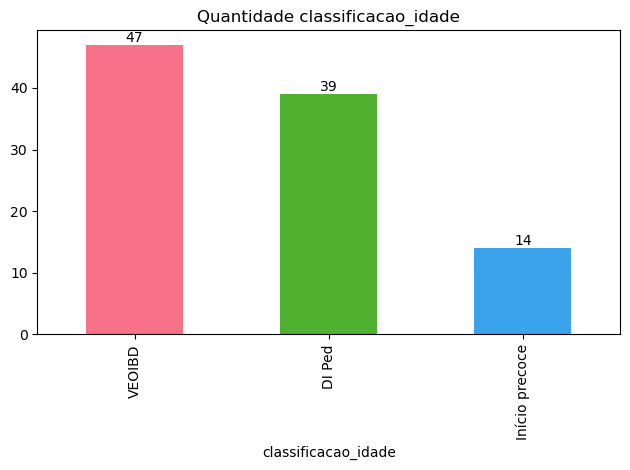

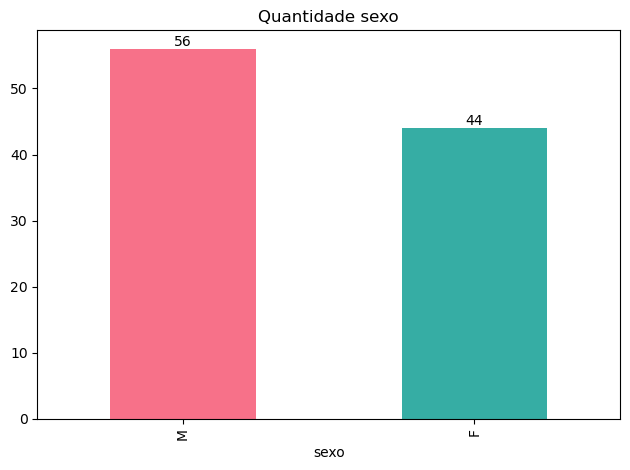

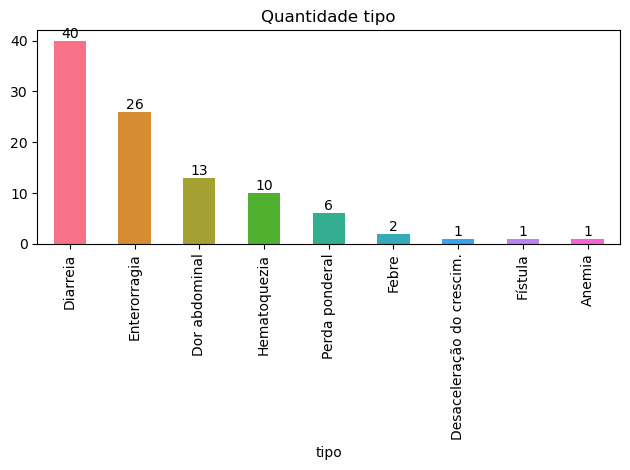

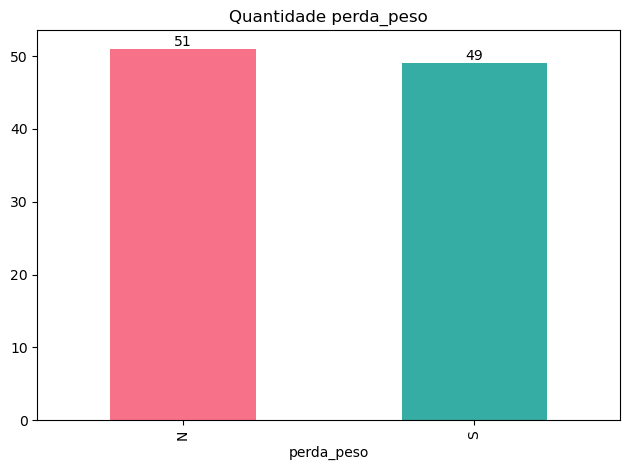

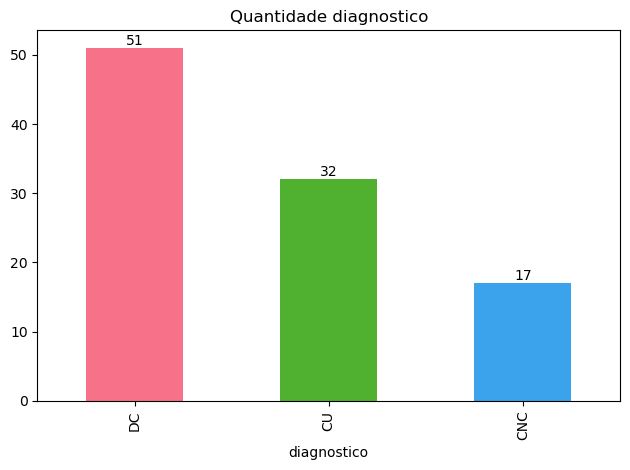

In [71]:
for categoria in dados_categoricos_df:
    # print(categoria)
    contagem = dados_df[categoria].value_counts()
    # print(contagem)
    cores = sns.color_palette("husl", len(contagem))
    ax = contagem.plot(kind="bar", color=cores)
    ax.set_title(f'Quantidade {categoria}')
    ax.set_xlabel(categoria)
    # ax.set_ylabel("Quantidade")  
    for container in ax.containers:
        ax.bar_label(container)
    # plt.xticks(rotation=0)
    # plt.tight_layout()
    # plt.show()  
    plt.tight_layout()
    plt.savefig(f"geral_{categoria}.png", dpi=300, bbox_inches="tight")
    plt.show()
    

# As mesmas coisinhas descritivas porem agora para as mulheres

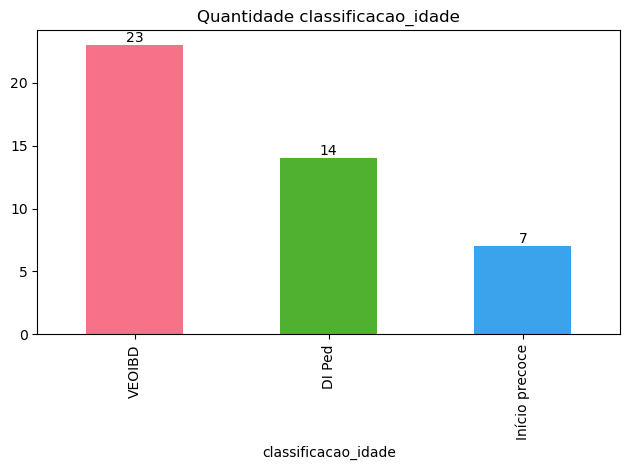

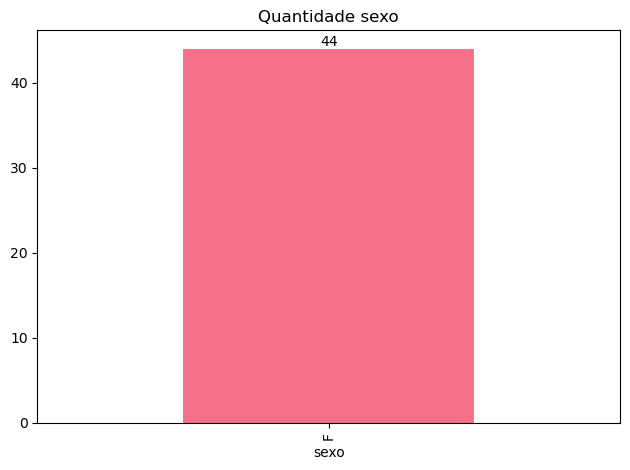

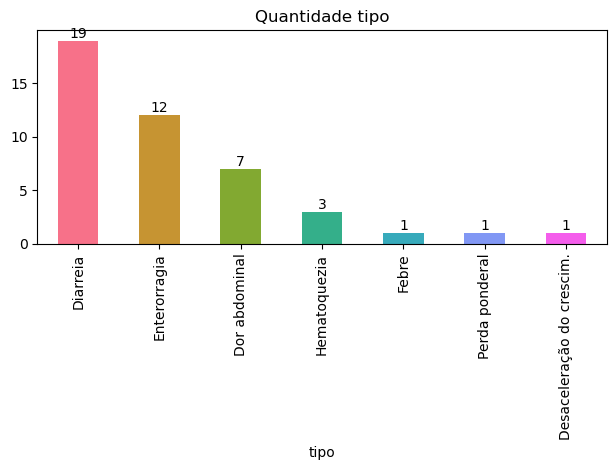

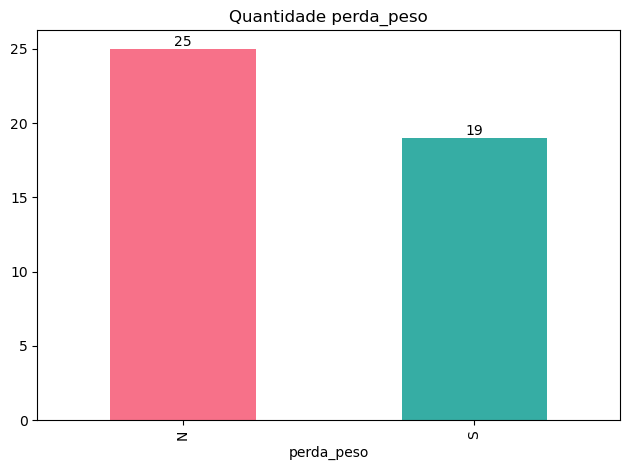

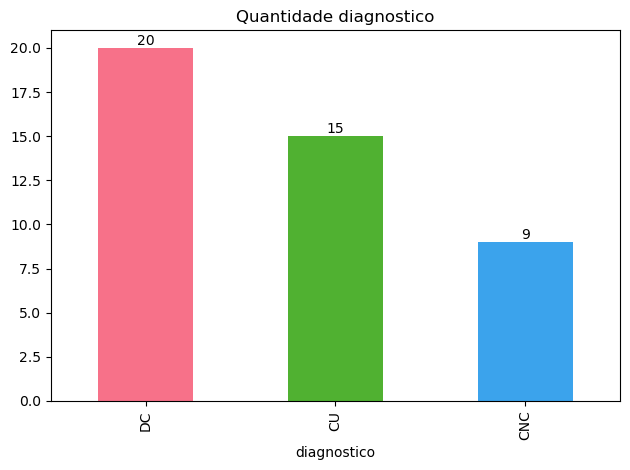

In [73]:
for categoria in mulheres_categoricos_df:
    # print(categoria)
    contagem = mulheres_categoricos_df[categoria].value_counts()
    # print(contagem)
    cores = sns.color_palette("husl", len(contagem))
    ax = contagem.plot(kind="bar", color=cores)
    ax.set_title(f'Quantidade {categoria}')
    ax.set_xlabel(categoria)
    # ax.set_ylabel("Quantidade")  
    for container in ax.containers:
        ax.bar_label(container)
    # plt.xticks(rotation=0)
    # plt.tight_layout()
    # plt.show()  
    plt.tight_layout()
    plt.savefig(f"mulheres_{categoria}.png", dpi=300, bbox_inches="tight")
    plt.show()

# # As mesmas coisinhas descritivas porem agora para as mulheres

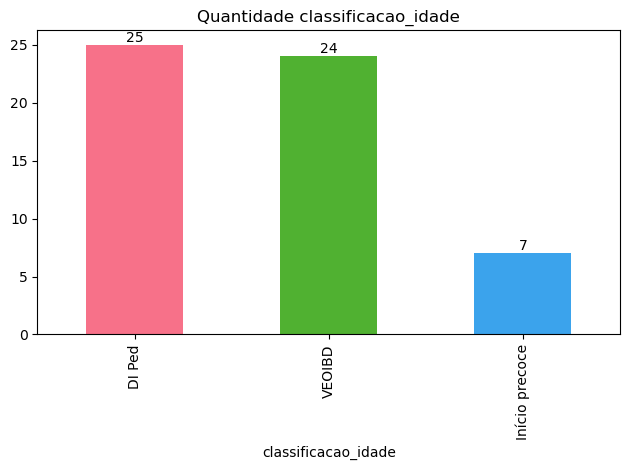

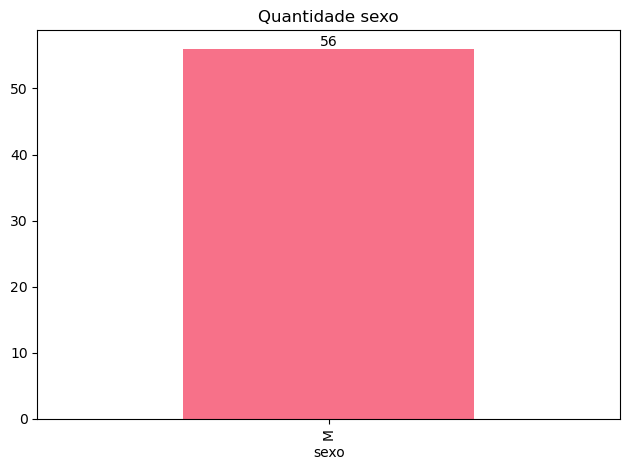

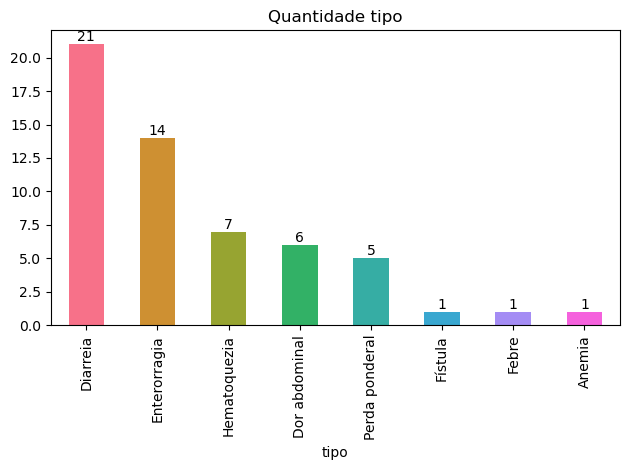

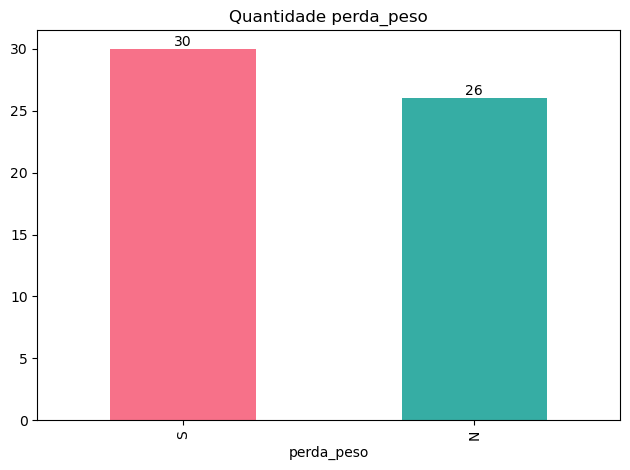

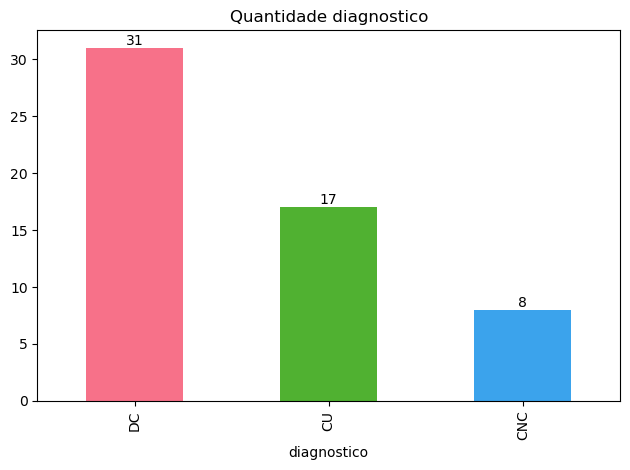

In [78]:
for categoria in homens_categoricos_df:
    # print(categoria)
    contagem = homens_categoricos_df[categoria].value_counts()
    # print(contagem)
    cores = sns.color_palette("husl", len(contagem))
    ax = contagem.plot(kind="bar", color=cores)
    ax.set_title(f'Quantidade {categoria}')
    ax.set_xlabel(categoria)
    # ax.set_ylabel("Quantidade")  
    for container in ax.containers:
        ax.bar_label(container)
    # plt.xticks(rotation=0)
    # plt.tight_layout()
    # plt.show()  
    plt.tight_layout()
    plt.savefig(f"homens_{categoria}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Tempo médio entre NASCIMENTO e INICIO SINTOMAS Geral

In [80]:
tempo_medio_inicio_sintomas_geral = dados_df.groupby('diagnostico')['idade_inicio_sintomas'].mean()
tempo_medio_inicio_sintomas_geral


diagnostico
CNC     44.882353
CU         74.375
DC     106.431373
Name: idade_inicio_sintomas, dtype: object

# Tempo médio entre NASCIMENTO e INICIO SINTOMAS Mulheres

In [53]:
tempo_medio_inicio_sintomas_mulheres = mulheres_df.groupby('diagnostico')['idade_inicio_sintomas'].mean()
tempo_medio_inicio_sintomas_mulheres
round(pd.Series(mulheres_df["idade_inicio_sintomas"].tolist()).describe(),2)

count     44.00
mean      80.23
std       53.66
min        3.00
25%       35.25
50%       69.00
75%      132.75
max      175.00
dtype: float64

# Tempo médio entre NASCIMENTO e INICIO SINTOMAS Homens

In [ ]:
tempo_medio_inicio_sintomas_homens = homens_df.groupby('diagnostico')['idade_inicio_sintomas'].mean()
tempo_medio_inicio_sintomas_homens
round(pd.Series(homens_df["idade_inicio_sintomas"].tolist()).describe(),2)

# Analise Bivariada.

In [82]:
def create_table(categoria1, categoria2):
    # Observada SEM margens: é a que entra no teste
    obs = pd.crosstab(categoria1, categoria2)

    chi2, p, dof, esp = chi2_contingency(obs)
    esp = pd.DataFrame(esp, index=obs.index, columns=obs.columns)

    # Resíduos de Pearson (sem coluna/linha Total)
    resid = ((obs - esp) / np.sqrt(esp)).round(2)

    # Versões com margens, só para exibição
    obs_total = pd.crosstab(categoria1, categoria2, margins=True, margins_name="Total")
    esp_total = esp.copy()
    esp_total["Total"] = esp_total.sum(axis=1)
    esp_total.loc["Total"] = esp_total.sum()

    n = obs.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))

    # --- Checagem do pressuposto (esperado < 5) ---
    pct_menor_5 = (esp < 5).values.mean() * 100
    esp_min = esp.values.min()
    pressuposto_ok = (pct_menor_5 <= 20) and (esp_min >= 1)

    teste_usado = "qui-quadrado"
    p_final = p
    aviso = ""

    if not pressuposto_ok:
        if obs.shape == (2, 2):
            _, p_final = fisher_exact(obs)
            teste_usado = "Fisher exato"
            aviso = "Esperado < 5: usado o teste exato de Fisher."
        else:
            teste_usado = "qui-quadrado (NÃO confiável)"
            aviso = "Esperado < 5 em tabela maior que 2x2: agrupe categorias raras."

    return {
        "observada": obs_total,
        "esperada": esp_total.round(2),
        "residuos": resid,
        "chi2": chi2,
        "p": p,
        "dof": dof,
        "cramers_v": cramers_v,
        "pct_esp_menor_5": pct_menor_5,
        "esp_min": esp_min,
        "pressuposto_ok": pressuposto_ok,
        "teste_usado": teste_usado,
        "p_final": p_final,
        "aviso": aviso,
    }

# Analise de associacao das variaveis categoricas dados_df

In [84]:
alpha = 0.05

In [86]:
colunas_categoricas = dados_categoricos_df.columns.tolist()
n = len(colunas_categoricas)

resultados_manual = []

# colunas_categoricas

analise_bivariada = []

for i in range(n):
    for j in range(n):
        if i < j:
            col1 = colunas_categoricas[i]
            col2 = colunas_categoricas[j]
            # print(col1,col2)
            res = create_table(dados_categoricos_df[col1],dados_categoricos_df[col2])
            # print(f"χ² = {res['chi2']:.2f} | p = {res['p_final']:.3f} | gl = {res['dof']} | V = {res['cramers_v']:.2f}")
            if res["p_final"] < alpha:
                print(f"{col1} x {col2}")
                print(f"χ² = {res['chi2']:.2f} | p = {res['p_final']:.3f} | gl = {res['dof']} | V = {res['cramers_v']:.2f}")
                if res["aviso"]:
                    print("Atenção:", res["aviso"])
                print(res["residuos"])
                print()

classificacao_idade x tipo
χ² = 31.44 | p = 0.012 | gl = 16 | V = 0.40
Atenção: Esperado < 5 em tabela maior que 2x2: agrupe categorias raras.
tipo                 Anemia  Desaceleração do crescim.  Diarreia  \
classificacao_idade                                                
DI Ped                 0.98                      -0.62     -0.15   
Início precoce        -0.37                      -0.37      1.01   
VEOIBD                -0.69                       0.77     -0.42   

tipo                 Dor abdominal  Enterorragia  Febre  Fístula  \
classificacao_idade                                                
DI Ped                        2.19         -1.61   0.25     0.98   
Início precoce                0.13         -1.38   1.36    -0.37   
VEOIBD                       -2.07          2.23  -0.97    -0.69   

tipo                 Hematoquezia  Perda ponderal  
classificacao_idade                                
DI Ped                      -0.96            1.09  
Início precoce     

# Analise de associacao das variaveis categoricas MULHERES

In [88]:
colunas_categoricas = mulheres_categoricos_df.columns.tolist()
n = len(colunas_categoricas)

resultados_manual = []

# colunas_categoricas

analise_bivariada = []

for i in range(n):
    for j in range(n):
        if i < j:
            col1 = colunas_categoricas[i]
            col2 = colunas_categoricas[j]
            # print(col1,col2)
            res = create_table(mulheres_categoricos_df[col1],mulheres_categoricos_df[col2])
            # print(f"χ² = {res['chi2']:.2f} | p = {res['p_final']:.3f} | gl = {res['dof']} | V = {res['cramers_v']:.2f}")
            if res["p_final"] < alpha:
                print(f"{col1} x {col2}")
                print(f"χ² = {res['chi2']:.2f} | p = {res['p_final']:.3f} | gl = {res['dof']} | V = {res['cramers_v']:.2f}")
                if res["aviso"]:
                    print("Atenção:", res["aviso"])
                print(res["residuos"])
                print()

classificacao_idade x tipo
χ² = 21.79 | p = 0.040 | gl = 12 | V = 0.50
Atenção: Esperado < 5 em tabela maior que 2x2: agrupe categorias raras.
tipo                 Desaceleração do crescim.  Diarreia  Dor abdominal  \
classificacao_idade                                                       
DI Ped                                   -0.56      0.79           1.86   
Início precoce                           -0.40      0.56          -0.11   
VEOIBD                                    0.66     -0.93          -1.39   

tipo                 Enterorragia  Febre  Hematoquezia  Perda ponderal  
classificacao_idade                                                     
DI Ped                      -1.44  -0.56         -0.98           -0.56  
Início precoce              -0.66   2.11         -0.69           -0.40  
VEOIBD                       1.49  -0.72          1.14            0.66  



/var/folders/67/sty1wlj57gz5hq6p23frp3pc0000gn/T/ipykernel_20950/4108378483.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))
/var/folders/67/sty1wlj57gz5hq6p23frp3pc0000gn/T/ipykernel_20950/4108378483.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))
/var/folders/67/sty1wlj57gz5hq6p23frp3pc0000gn/T/ipykernel_20950/4108378483.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))
/var/folders/67/sty1wlj57gz5hq6p23frp3pc0000gn/T/ipykernel_20950/4108378483.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (n * (min(obs.shape) - 1)))


# Função que retorna as tabelas de contingencias para duas categorias

In [90]:
import matplotlib.pyplot as plt
import pandas as pd
import textwrap

PALETA = ['#2E5077', '#E8A54B', '#6FA88A', '#B85C6B', '#7B6FA8', '#4B8FA8',
          '#C4A35A', '#5B8C85', '#9B6B9E']  # até 9 cores distintas
COR_HEADER = '#2E5077'
COR_TOTAL_BG = '#F0EDE5'
COR_GRID = '#D9D9D9'

def plotar_com_tabela(tabela, titulo=None):
    plt.close('all')  # <- evita sobreposição de figuras/legendas de chamadas anteriores no loop
    
    dados_plot = tabela.drop(index='Total', errors='ignore').drop(columns='Total', errors='ignore')
    n_categorias = dados_plot.shape[1]
    cores = (PALETA * ((n_categorias // len(PALETA)) + 1))[:n_categorias]  # repete paleta se precisar
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.3, 1.3]})
    
    # --- Painel 1: tabela ---
    axes[0].axis('off')
    tabela_texto = tabela.reset_index()
    n_cols = len(tabela_texto.columns)
    
    # quebra nomes de coluna longos em múltiplas linhas
    largura_max_char = max(10, 40 // n_cols)  # menos colunas = pode ter linha mais larga
    colunas_wrap = ['\n'.join(textwrap.wrap(str(c), largura_max_char)) for c in tabela_texto.columns]
    
    larguras = []
    for col_original, col_wrap in zip(tabela_texto.columns, colunas_wrap):
        max_len_dado = tabela_texto[col_original].astype(str).map(len).max()
        max_len_header = max(len(linha) for linha in col_wrap.split('\n'))
        larguras.append(max(max_len_dado, max_len_header))
    total_largura = sum(larguras)
    col_widths = [l / total_largura for l in larguras]
    
    # fonte menor quando há muitas colunas
    fonte_tabela = 10 if n_cols <= 5 else (8 if n_cols <= 8 else 7)
    
    tab = axes[0].table(
        cellText=tabela_texto.values,
        colLabels=colunas_wrap,
        cellLoc='center',
        loc='center',
        colWidths=col_widths
    )
    tab.auto_set_font_size(False)
    tab.set_fontsize(fonte_tabela)
    tab.scale(1, 2.4 if n_cols > 5 else 2.0)  # linhas mais altas para caber o cabeçalho quebrado
    
    for (row, col), cell in tab.get_celld().items():
        cell.set_edgecolor(COR_GRID)
        if row == 0:
            cell.set_facecolor(COR_HEADER)
            cell.set_text_props(color='white', weight='bold')
            cell.set_height(cell.get_height() * 1.8)  # espaço extra pro texto quebrado
        elif tabela_texto.iloc[row-1, 0] == 'Total':
            cell.set_facecolor(COR_TOTAL_BG)
            cell.set_text_props(weight='bold', color=COR_HEADER)
        else:
            cell.set_facecolor('white' if row % 2 else '#FAFAFA')
    
    axes[0].set_title('Tabela de contingência', fontsize=13, weight='bold',
                       color=COR_HEADER, pad=20)
    
    # --- Painel 2: gráfico de barras agrupadas ---
    dados_plot.plot(kind='bar', ax=axes[1], color=cores,
                     edgecolor='white', linewidth=0.8, width=0.75)
    axes[1].set_title(titulo or '', fontsize=13, weight='bold', color=COR_HEADER, pad=12)
    axes[1].set_ylabel('N° de casos', fontsize=10)
    axes[1].set_xlabel(dados_plot.index.name, fontsize=10)
    axes[1].tick_params(axis='x', rotation=20)
    
    # legenda: fora do gráfico, fonte menor se tiver muitas categorias
    fonte_legenda = 9 if n_categorias <= 5 else 7
    axes[1].legend(title=dados_plot.columns.name, frameon=False,
                    bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=fonte_legenda)
    
    axes[1].spines['top'].set_visible(False)
    axes[1].spines['right'].set_visible(False)
    axes[1].grid(axis='y', color=COR_GRID, linewidth=0.6, alpha=0.6, zorder=0)
    axes[1].set_axisbelow(True)
    
    plt.tight_layout()
    plt.show()


In [92]:
def create_table2(categoria1,categoria2):
    tres_df = []
    tabela_c1_c2 = pd.crosstab(
        categoria1,
        categoria2,
        margins=True,
        margins_name='Total'
    )
    tres_df.append(tabela_c1_c2)
    chi2, p, dof, esp = chi2_contingency(tabela_c1_c2)
   
    tabela_esperada_c1_c2_df = pd.DataFrame(esp, index=tabela_c1_c2.index, columns=tabela_c1_c2.columns)
    tres_df.append(tabela_esperada_c1_c2_df)

    # Resíduos padronizados ajustados (Pearson)
    resid_c1_c2 = (tabela_c1_c2 - tabela_esperada_c1_c2_df) / np.sqrt(tabela_esperada_c1_c2_df)
    resid_c1_c2 = resid_c1_c2.drop(columns=["Total"])
    resid_c1_c2 = resid_c1_c2[:-1]
    resid_c1_c2.round(2)

    tres_df.append(resid_c1_c2)
    # print(tres_df)
    return tres_df

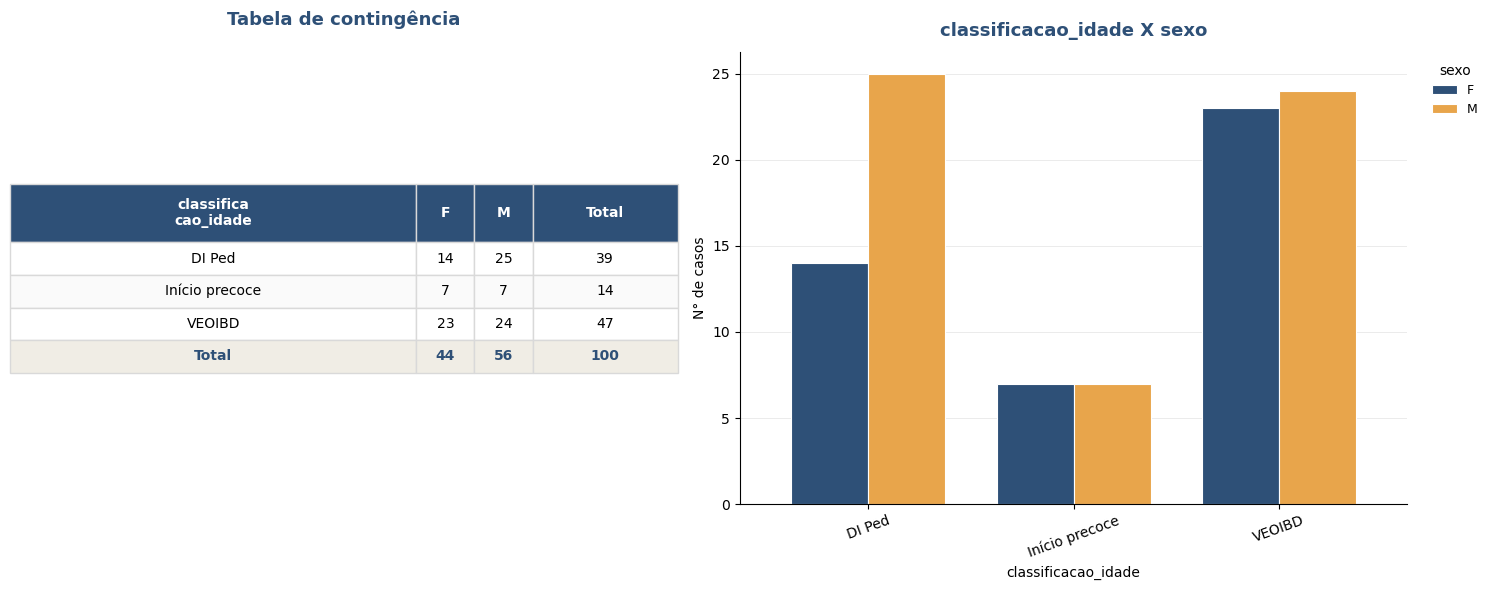

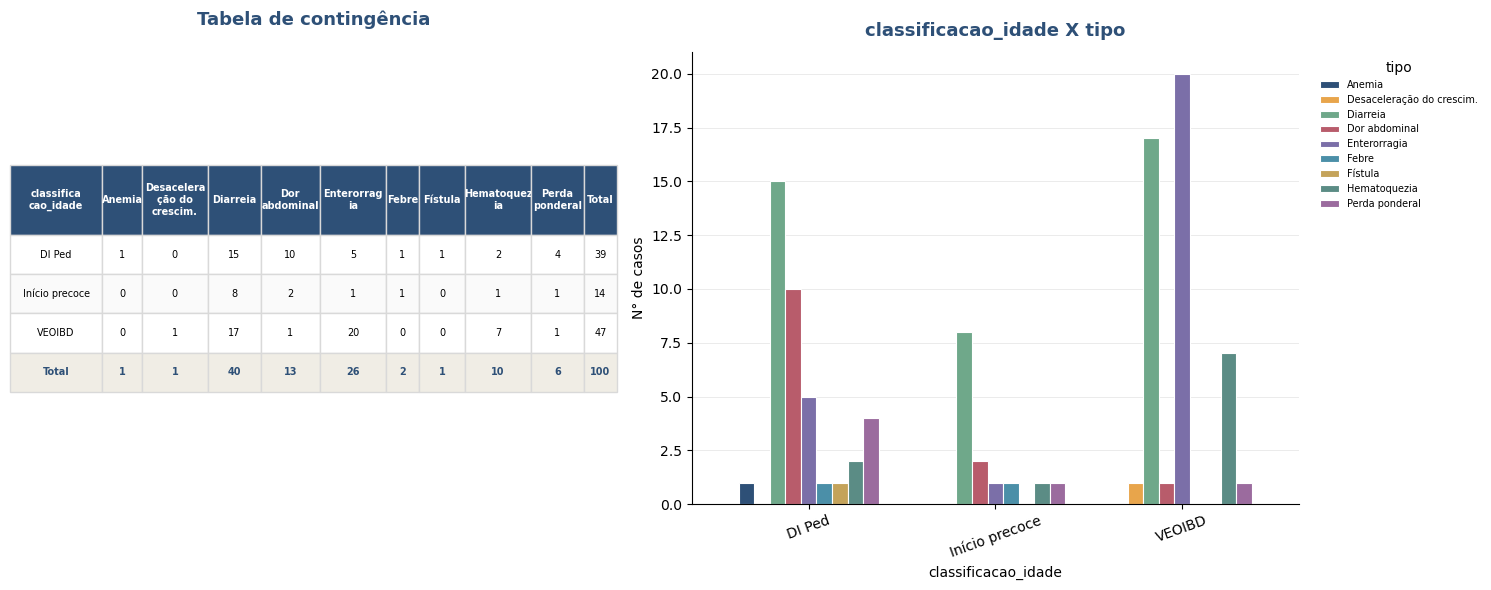

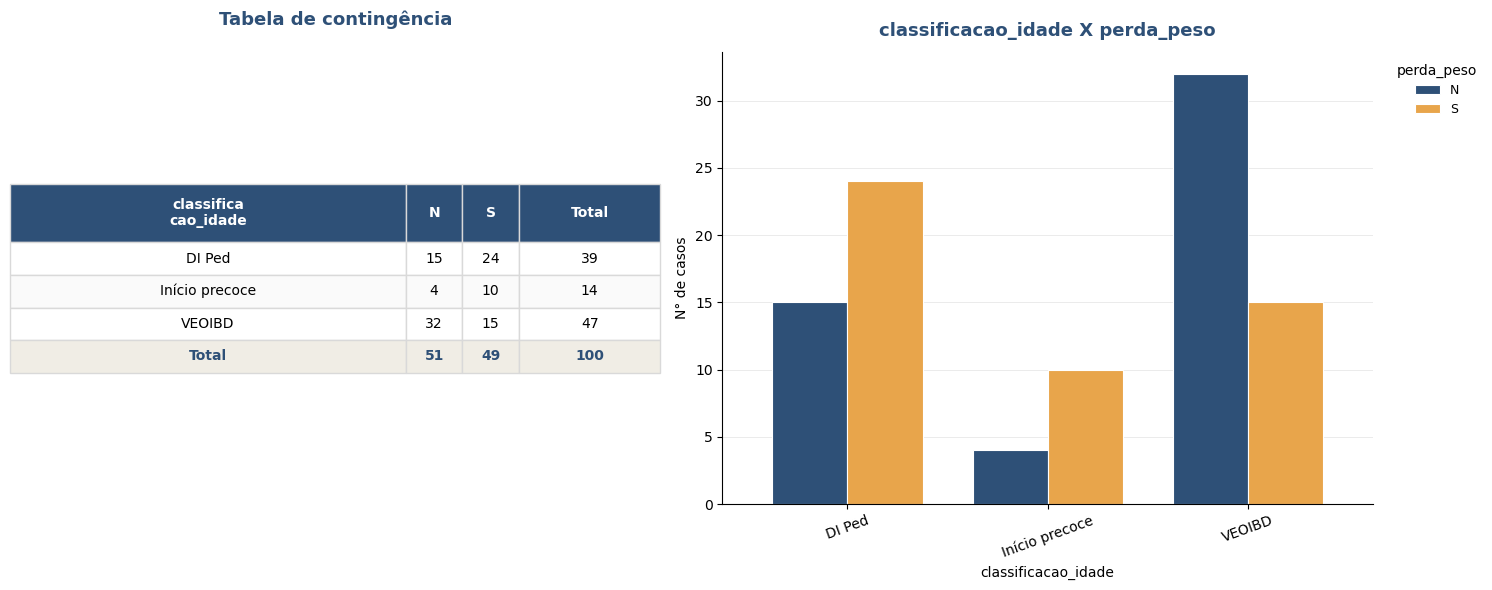

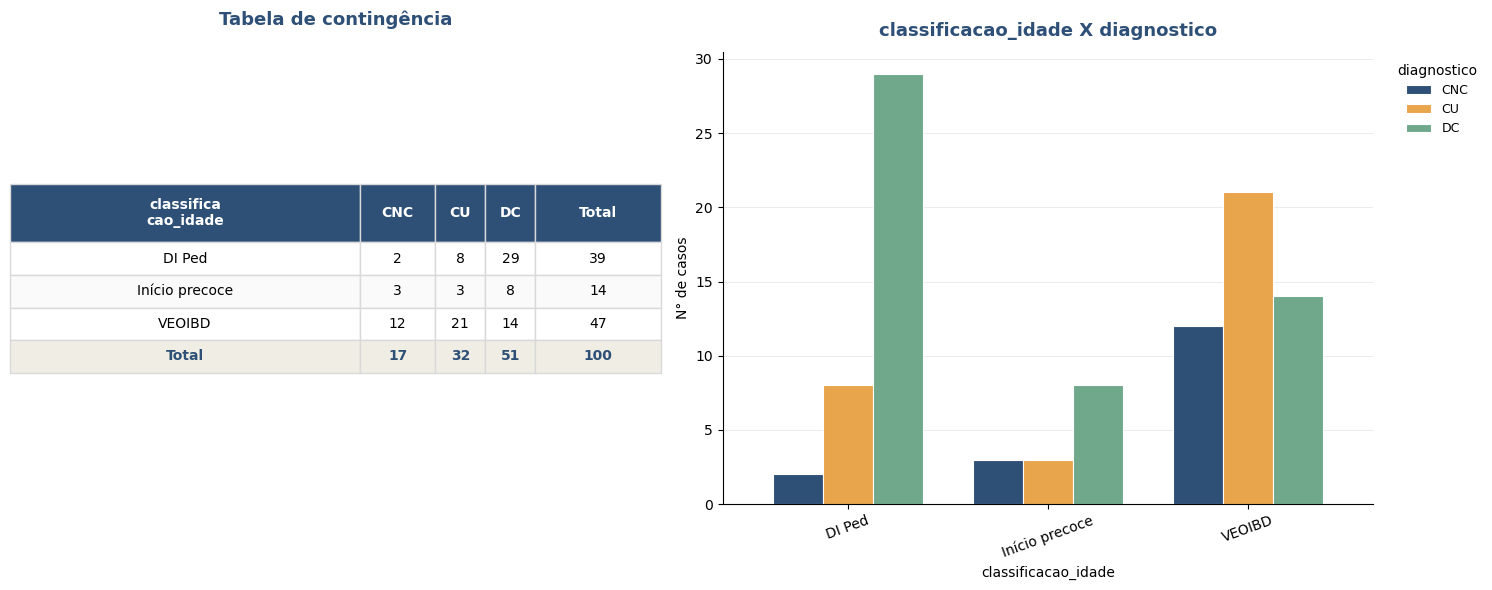

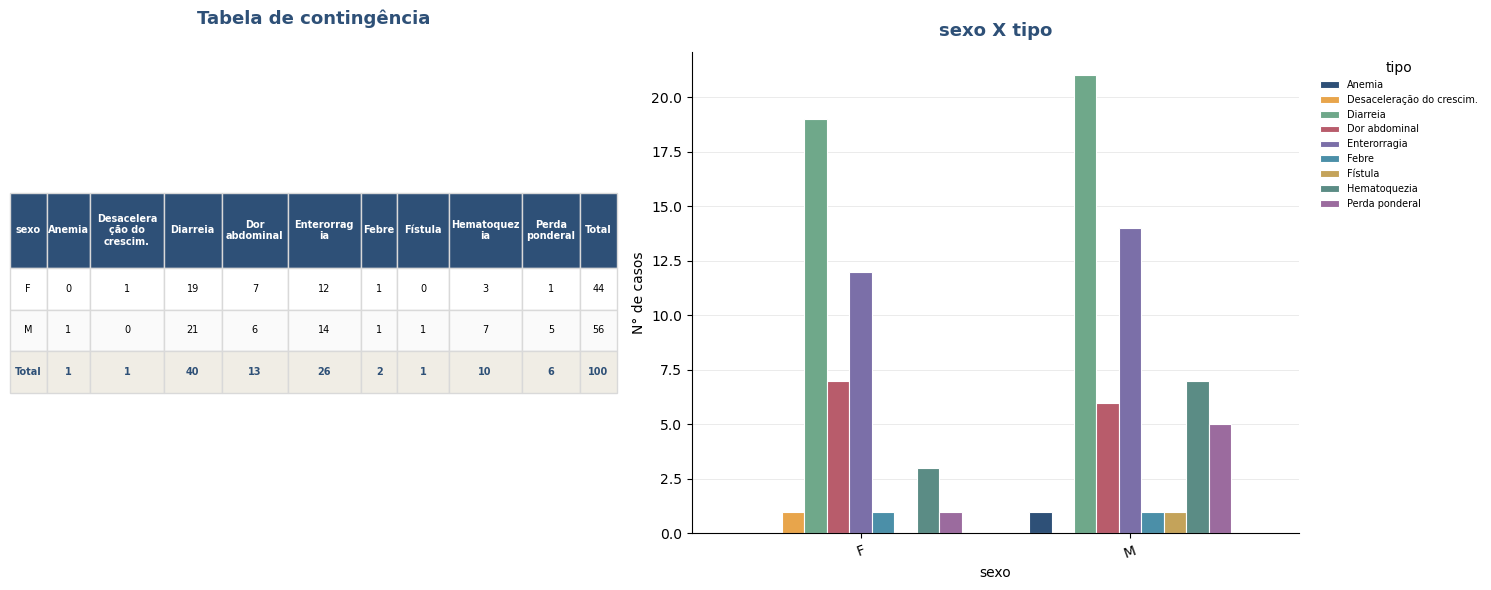

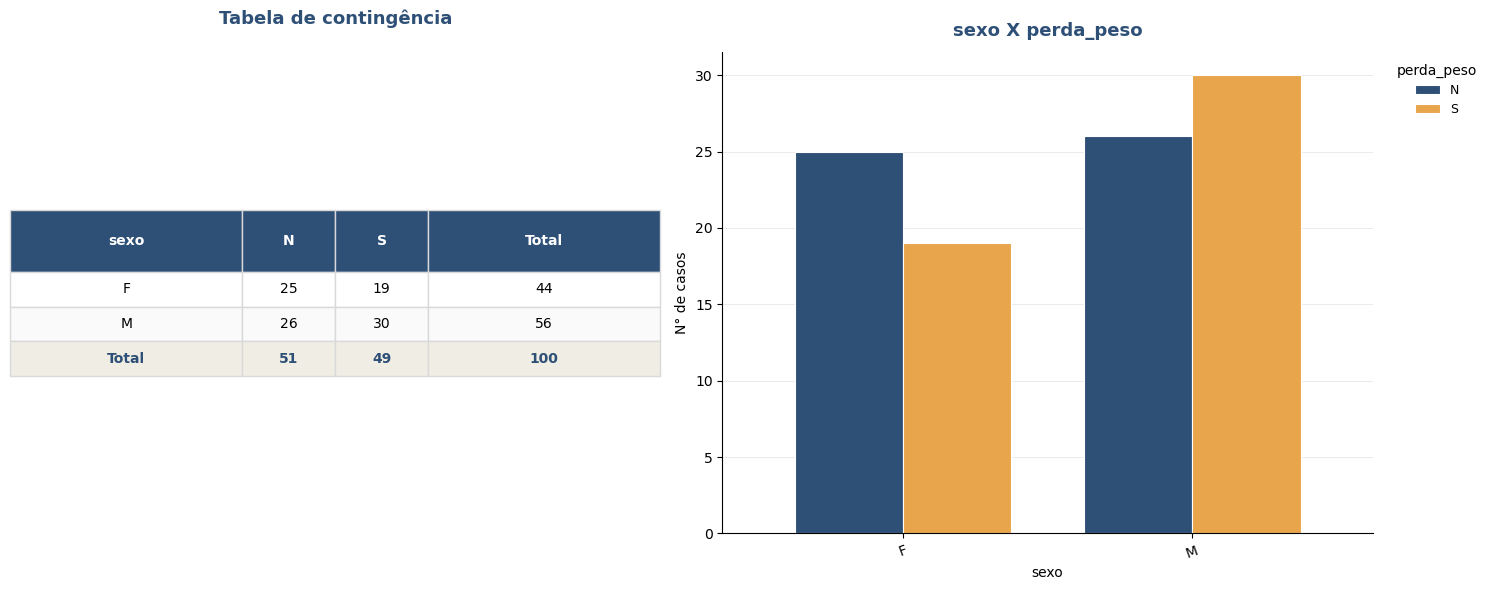

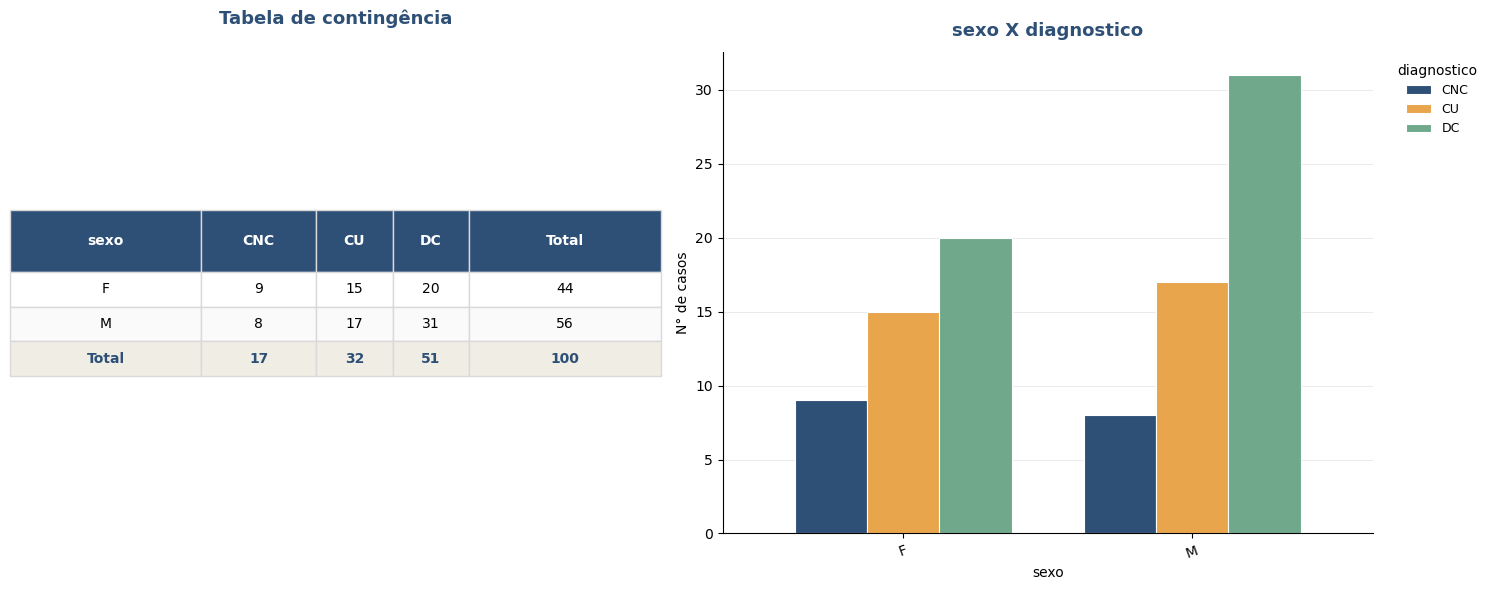

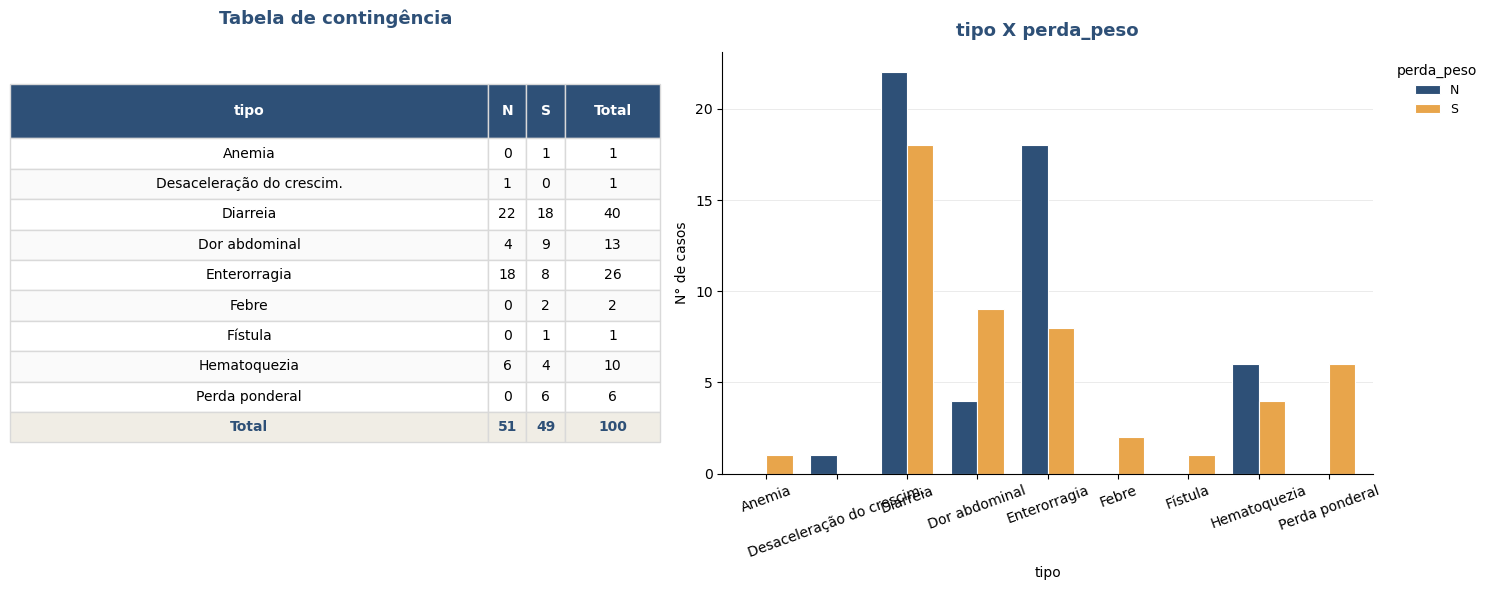

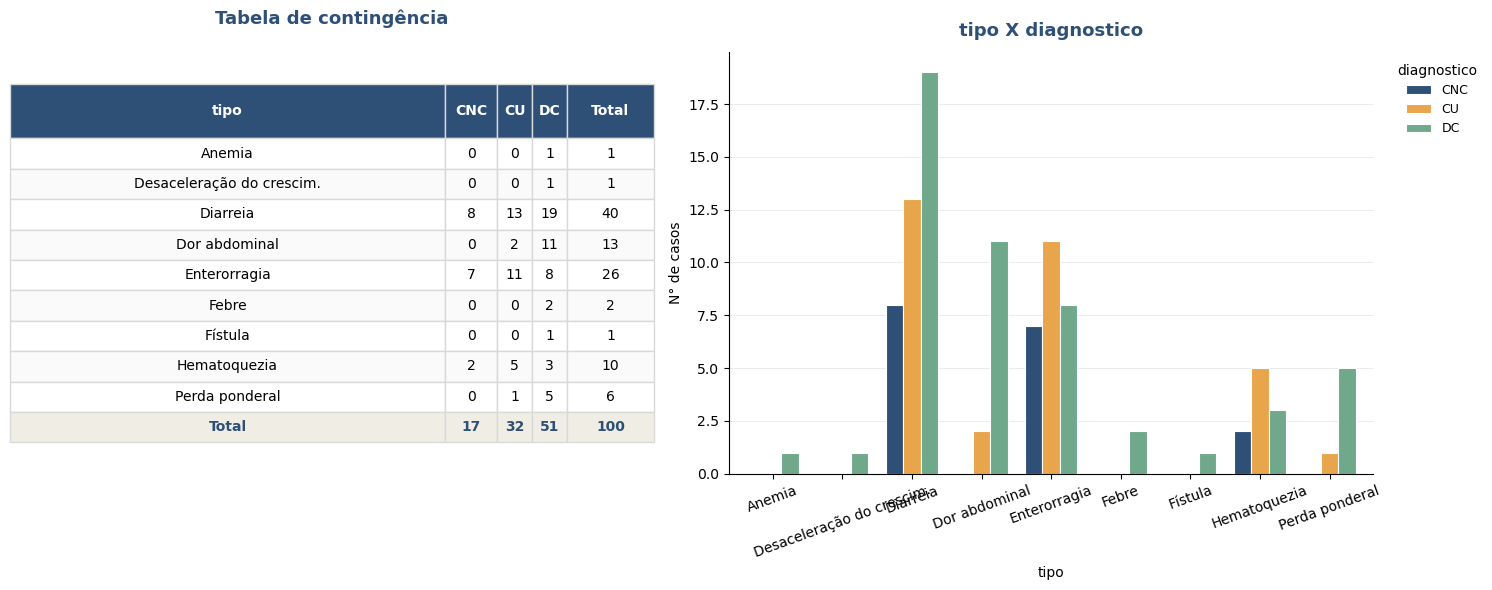

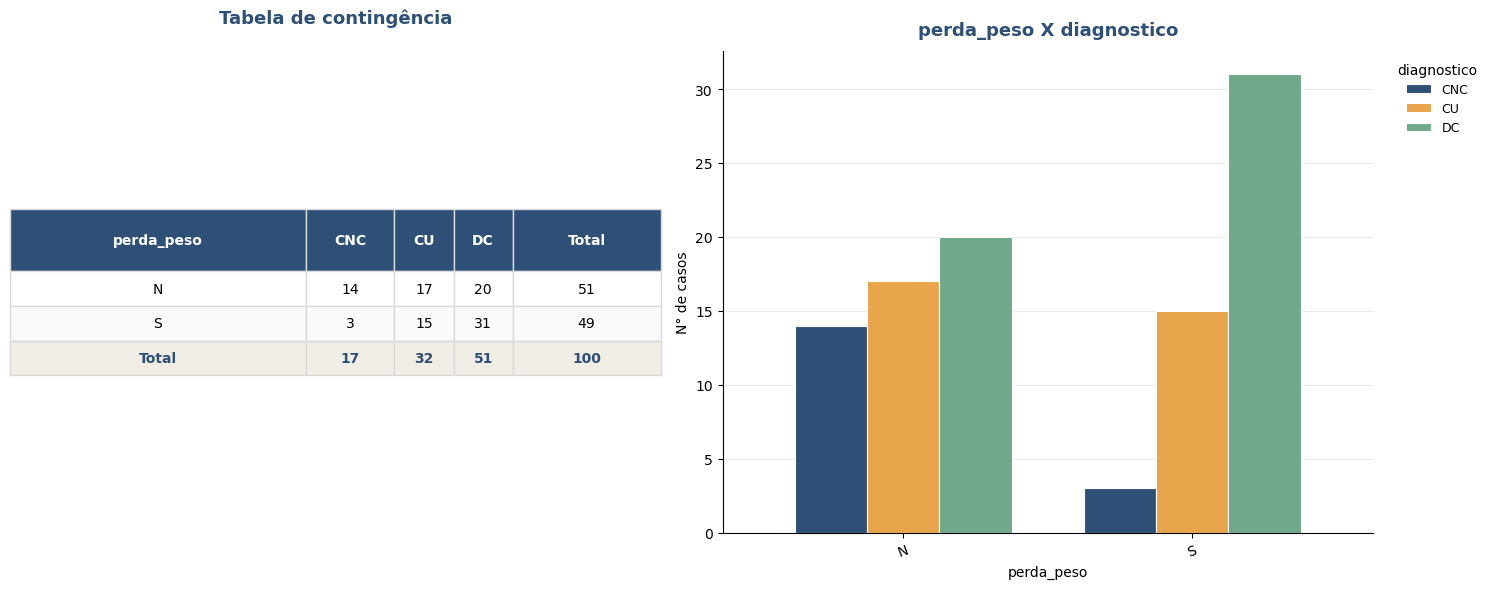

In [94]:
colunas_categoricas = dados_categoricos_df.columns.tolist()
n = len(colunas_categoricas)

resultados_manual = []

# colunas_categoricas

analise_bivariada = []

for i in range(n):
    for j in range(n):
        if i < j:
            col1 = colunas_categoricas[i]
            col2 = colunas_categoricas[j]
            
            col1_col2_tres_df = create_table2(dados_categoricos_df[col1],dados_categoricos_df[col2])
          
         
            analise_bivariada.append(col1_col2_tres_df[0])
            plotar_com_tabela(col1_col2_tres_df[0],f'{col1} X {col2}')


In [ ]:
# //*
colunas_categoricas_mulheres = mulheres_categoricos_df.columns.tolist()
n = len(colunas_categoricas_mulheres)

resultados_manual_teste = []

# colunas_categoricas

analise_bivariada_mulheres = []

for i in range(n):
    for j in range(n):
        # j = j + 1
        if i < j:
            col1 = colunas_categoricas_mulheres[i]
            col2 = colunas_categoricas_mulheres[j]
            
            col1_col2_tres_df = create_table(mulheres_categoricos_df[col1],mulheres_categoricos_df[col2])
          
         
            analise_bivariada.append(col1_col2_tres_df[0])
            plotar_com_tabela(col1_col2_tres_df[0],f'{col1} X {col2}')

# //*

In [ ]:
### tentativa feia muito feia d um modelo

In [ ]:
%pip install lifelines

In [ ]:
# Análise de sobrevivência - tempo (meses) do início dos sintomas até a 1ª colonoscopia
# Cada bloco "# %%" é uma célula: cole no Jupyter na ordem, depois de ter `dados_df` carregado.
# Instalação (uma vez): pip install lifelines

# %% 0. Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from lifelines import KaplanMeierFitter, CoxPHFitter, LogNormalAFTFitter, WeibullAFTFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
from lifelines.plotting import add_at_risk_counts
from lifelines.utils import median_survival_times

os.makedirs("figuras", exist_ok=True)

# %% 1. Preparar a base
df = dados_df.copy()

# datas (dd/mm/aaaa)
cols_data = ["data_nascimento", "data_primeira_consulta",
             "data_inicio_sintomas", "data_primeira_colonoscopia"]
for c in cols_data:
    df[c] = pd.to_datetime(df[c], dayfirst=True, errors="coerce")
print("Datas não lidas (NaT):\n", df[cols_data].isna().sum(), "\n")

# textos limpos
for c in ["tipo", "diagnostico", "sexo", "perda_peso", "classificacao_idade"]:
    df[c] = df[c].astype(str).str.strip()

# desfecho: meses até a 1ª colonoscopia. Todos têm o evento (não há censura).
df["tempo"] = df["intervalo_sintomas_primeira_colonoscopia"].astype(float)
df["evento"] = 1

# checagens: tempo > 0 e coerência com as datas (diferença de 1 mês é esperada por arredondamento)
print("Tempo mínimo:", df["tempo"].min(), "| tempos <= 0:", (df["tempo"] <= 0).sum())
meses_calc = ((df["data_primeira_colonoscopia"].dt.year - df["data_inicio_sintomas"].dt.year) * 12
              + (df["data_primeira_colonoscopia"].dt.month - df["data_inicio_sintomas"].dt.month))
dif = (meses_calc - df["tempo"]).abs()
print("Linhas com diferença > 1 mês entre datas e intervalo:", (dif > 1).sum())
print("Colonoscopia anterior ao início dos sintomas:",
      (df["data_primeira_colonoscopia"] < df["data_inicio_sintomas"]).sum(), "\n")

# covariáveis
df["sangramento"] = df["tipo"].str.lower().isin(["enterorragia", "hematoquezia"]).astype(int)
df["idade_anos"] = df["idade_inicio_sintomas"] / 12
df["menino"] = (df["sexo"] == "M").astype(int)
df["perda_peso_bin"] = (df["perda_peso"] == "S").astype(int)
df["veoibd"] = (df["idade_anos"] < 6).astype(int)
df["dx_DC"] = (df["diagnostico"] == "DC").astype(int)   # referência: CNC
df["dx_CU"] = (df["diagnostico"] == "CU").astype(int)
df["colono_apos_consulta"] = (df["data_primeira_colonoscopia"] >= df["data_primeira_consulta"]).astype(int)

print(df[["tempo", "idade_anos", "sangramento", "menino", "perda_peso_bin", "veoibd"]].describe().round(2))
print(df["tipo"].value_counts(), "\n", df["diagnostico"].value_counts(), "\n")

# %% 2. Kaplan-Meier geral
kmf = KaplanMeierFitter().fit(df["tempo"], df["evento"], label="Todos")
print("Mediana (meses):", kmf.median_survival_time_)
print(median_survival_times(kmf.confidence_interval_))
for m in [6, 12, 24]:
    print(f"Sem diagnóstico após {m} meses: {kmf.predict(m):.1%}")

ax = kmf.plot_survival_function()
ax.set_xlabel("Meses desde o início dos sintomas")
ax.set_ylabel("Proporção ainda sem colonoscopia")
add_at_risk_counts(kmf, ax=ax)
plt.tight_layout(); plt.savefig("figuras/km_geral.png", dpi=200); plt.show()

# %% 3. Kaplan-Meier por grupo + log-rank
def km_por_grupo(data, col, titulo, arquivo):
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    ajustes = []
    for g, sub in data.groupby(col):
        k = KaplanMeierFitter().fit(sub["tempo"], sub["evento"], label=f"{g} (n={len(sub)})")
        k.plot_survival_function(ax=ax, ci_alpha=0.12)
        ajustes.append(k)
        print(f"  {col}={g}: mediana = {k.median_survival_time_:.1f} meses")
    p = multivariate_logrank_test(data["tempo"], data[col], data["evento"]).p_value
    ax.set_title(f"{titulo}  (log-rank p = {p:.3f})")
    ax.set_xlabel("Meses desde o início dos sintomas")
    ax.set_ylabel("Proporção ainda sem colonoscopia")
    add_at_risk_counts(*ajustes, ax=ax)
    plt.tight_layout(); plt.savefig(arquivo, dpi=200); plt.show()

km_por_grupo(df, "sangramento", "Sangramento retal como sintoma inicial", "figuras/km_sangramento.png")
km_por_grupo(df, "classificacao_idade", "Classificação etária", "figuras/km_idade.png")
km_por_grupo(df, "diagnostico", "Tipo de DII", "figuras/km_diagnostico.png")
km_por_grupo(df, "sexo", "Sexo", "figuras/km_sexo.png")
km_por_grupo(df, "perda_peso", "Perda ponderal", "figuras/km_perda_peso.png")

# %% 4. Cox univariado (HR > 1 = diagnóstico mais rápido)
def ajustar_cox(cols, data=df, penalizer=0.0):
    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(data[["tempo", "evento"] + cols], duration_col="tempo", event_col="evento")
    return cph

colunas_resumo = ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
uni = []
for v in ["sangramento", "idade_anos", "menino", "perda_peso_bin", "dx_DC", "dx_CU"]:
    s = ajustar_cox([v]).summary.loc[v, colunas_resumo]
    s.name = v
    uni.append(s)
print(pd.DataFrame(uni).round(3))

# %% 5. Cox multivariado principal: sangramento ajustado por idade e sexo
cols_base = ["sangramento", "idade_anos", "menino"]
cph0 = ajustar_cox(cols_base)
cph0.print_summary(decimals=3)

# riscos proporcionais (p < 0,05 indica violação)
proportional_hazard_test(cph0, df[["tempo", "evento"] + cols_base], time_transform="rank").print_summary()

# %% 6. Interação idade x sangramento (a hipótese vinda da análise estratificada)
df["sang_x_idade"] = df["sangramento"] * df["idade_anos"]
cols_int = cols_base + ["sang_x_idade"]
cph1 = ajustar_cox(cols_int)
cph1.print_summary(decimals=3)

lr = 2 * (cph1.log_likelihood_ - cph0.log_likelihood_)
print(f"Teste da razão de verossimilhança da interação: chi2 = {lr:.2f}, p = {chi2.sf(lr, 1):.3f}")

# HR do sangramento em cada idade (com IC 95%)
b = cph1.params_
V = cph1.variance_matrix_
linhas = []
for a in [1, 2, 4, 6, 8, 10, 12]:
    est = b["sangramento"] + b["sang_x_idade"] * a
    var = V.loc["sangramento", "sangramento"] + a**2 * V.loc["sang_x_idade", "sang_x_idade"] \
          + 2 * a * V.loc["sangramento", "sang_x_idade"]
    se = np.sqrt(var)
    linhas.append({"idade (anos)": a, "HR": np.exp(est),
                   "IC95% inf": np.exp(est - 1.96 * se), "IC95% sup": np.exp(est + 1.96 * se)})
print(pd.DataFrame(linhas).round(2))

# %% 7. Modelo AFT (sensibilidade): exp(coef) = razão de tempos (> 1 = diagnóstico mais lento)
for Modelo in (LogNormalAFTFitter, WeibullAFTFitter):
    aft = Modelo().fit(df[["tempo", "evento"] + cols_base], duration_col="tempo", event_col="evento")
    print(Modelo.__name__, "| AIC:", round(aft.AIC_, 1))
    aft.print_summary(decimals=3)

# %% 8. Análises de sensibilidade: o efeito do sangramento muda?
cenarios = {
    "Principal (sangramento + idade + sexo)": (df, cols_base),
    "+ perda ponderal": (df, cols_base + ["perda_peso_bin"]),
    "+ tipo de DII (DC, CU vs CNC)": (df, cols_base + ["dx_DC", "dx_CU"]),
    "Sem tempos > 40 meses": (df[df["tempo"] <= 40], cols_base),
    "Só colonoscopia após a 1ª consulta no HC": (df[df["colono_apos_consulta"] == 1], cols_base),
}
res = []
for nome, (dados, cols) in cenarios.items():
    m = ajustar_cox(cols, data=dados).summary.loc["sangramento", colunas_resumo]
    m["n"] = len(dados)
    m.name = nome
    res.append(m)
print(pd.DataFrame(res).round(3))